### Step 1: Import Required Libraries

Import OpenCV for image processing, Matplotlib for displaying images, and NumPy for numerical operations.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

### Step 2: Load two sample images

Load two sample images using OpenCV's `imread()` function. Make sure both images are available in the same directory as your Jupyter Notebook.

In [2]:
# Load the two sample images
img1 = cv2.imread('Exercise2_image1.jpg')
img2 = cv2.imread('Exercise2_image2.jpg')

# Check whether images are loaded successfully
if img1 is None or img2 is None:
    print("Error: Unable to load images. Check file paths.")
else:
    print("Both images loaded successfully.")

    print("Image 1 dimensions:", img1.shape)
    print("Image 2 dimensions:", img2.shape)

Both images loaded successfully.
Image 1 dimensions: (4392, 7372, 3)
Image 2 dimensions: (5291, 7932, 3)


### Step 3: Resize images to matching dimensions

For weighted blending, both images must have identical dimensions. Therefore, resize the second image to match the dimensions of the first image.

In [3]:
# Get dimensions of the first image
height, width = img1.shape[:2]

# Resize the second image
img2_resized = cv2.resize(img2, (width, height))

print("Image 1 dimensions:", img1.shape)
print("Resized Image 2 dimensions:", img2_resized.shape)

Image 1 dimensions: (4392, 7372, 3)
Resized Image 2 dimensions: (4392, 7372, 3)



### Step 4: Perform Weighted Image Blending

Use OpenCV's `cv2.addWeighted()` function to combine the two images.

**Blending Formula:**

$$
Output = \alpha \times Image1 + \beta \times Image2 + \gamma
$$

**Parameters:**
- $\alpha = 0.6$ (60% contribution from Image 1)
- $\beta = 0.4$ (40% contribution from Image 2)
- $\gamma = 0$ (brightness adjustment)

The resulting image combines both input images according to their respective weights.

In [4]:
# Define blending weights
alpha = 0.6
beta = 0.4
gamma = 0

# Blend the two images
blended_image = cv2.addWeighted(
    img1, alpha,
    img2_resized, beta,
    gamma
)

print("Image blending completed successfully.")

Image blending completed successfully.


### Step 5: Display original and blended images

Display both original images and the resulting blended image using Matplotlib.

OpenCV loads images in BGR format, whereas Matplotlib expects RGB format. Therefore, convert the images before displaying them.

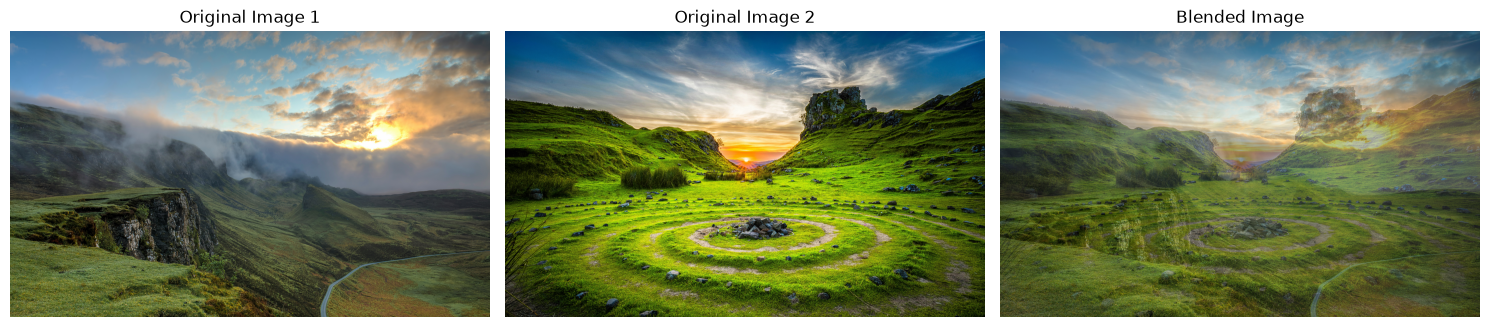

In [5]:
# Convert BGR images to RGB format
img1_rgb = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
img2_rgb = cv2.cvtColor(img2_resized, cv2.COLOR_BGR2RGB)
blended_rgb = cv2.cvtColor(blended_image, cv2.COLOR_BGR2RGB)

# Display all three images
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img1_rgb)
plt.title("Original Image 1")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(img2_rgb)
plt.title("Original Image 2")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(blended_rgb)
plt.title("Blended Image")
plt.axis('off')

plt.tight_layout()
plt.show()

### Step 6: Save the original and blended images

Save all three images using OpenCV's `imwrite()` function so that they can be accessed later.

In [7]:
# Save the images
cv2.imwrite('original_image1.jpg', img1)
cv2.imwrite('original_image2.jpg', img2_resized)
cv2.imwrite('Exercise2_blended_output.jpg', blended_image)

print("All images saved successfully!")

All images saved successfully!
